In [1]:
%pip install -q supervision scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path

PROJECT = Path.cwd().parent
CLIPS = PROJECT / "data" / "clips"
print(PROJECT)
from pathlib import Path
PROJECT = Path.cwd().parent

c:\Users\seree\OneDrive\Desktop\FalseNine


In [2]:
from pathlib import Path
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import supervision as sv
from ultralytics import YOLO

PROJECT = Path.cwd().parent
VIDEOS = PROJECT / "data" / "videos"
OUT = PROJECT / "outputs" / "04_tracking"
OUT.mkdir(parents=True, exist_ok=True)

videos = sorted(VIDEOS.glob("*.mp4"))
for i, v in enumerate(videos): print(i, v.name)

VIDEO = videos[0]          # change the number to try another clip
START, N_FRAMES = 300, 150 # skip the pre-kickoff part; 150 frames = 6 s, about 4-5 min on your CPU
PERSON_CONF = 0.30
BALL_CONF = 0.10

model = YOLO(PROJECT / "models" / "falsenine_det.pt")
cap = cv2.VideoCapture(str(VIDEO))
FPS = cap.get(cv2.CAP_PROP_FPS) or 25
print(VIDEO.name, "frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), "fps:", FPS)
cap.release()

0 SNGS-021.mp4
1 SNGS-022.mp4
2 SNGS-023.mp4
SNGS-021.mp4 frames: 750 fps: 25.0


In [8]:
def shirt_color(frame, box):
    """Average color of the upper body, ignoring green grass pixels."""
    x1, y1, x2, y2 = [int(v) for v in box]
    h, w = y2 - y1, x2 - x1
    if h < 10 or w < 4: return [np.nan] * 3
    crop = frame[y1 + int(.15 * h): y1 + int(.55 * h), x1 + int(.25 * w): x2 - int(.25 * w)]
    if crop.size == 0: return [np.nan] * 3
    hsv = cv2.cvtColor(crop, cv2.COLOR_BGR2HSV)
    grass = (hsv[..., 0] > 35) & (hsv[..., 0] < 85) & (hsv[..., 1] > 60)
    px = crop[~grass]
    if len(px) < 5: return [np.nan] * 3
    return list(np.median(px, axis=0)[::-1])      # RGB

# Detection only (no tracking yet). Slow: about 5 minutes. Run it once.
dets = []
cap = cv2.VideoCapture(str(VIDEO))
cap.set(cv2.CAP_PROP_POS_FRAMES, START)
for k in range(N_FRAMES):
    ok, frame = cap.read()
    if not ok: break
    res = model.predict(frame, imgsz=1280, conf=BALL_CONF, verbose=False)[0]
    boxes = res.boxes.xyxy.cpu().numpy()
    classes = res.boxes.cls.cpu().numpy().astype(int)
    confs = res.boxes.conf.cpu().numpy()
    for (x1, y1, x2, y2), c, p in zip(boxes, classes, confs):
        if c != 0 and p >= PERSON_CONF:
            r, g, b = shirt_color(frame, (x1, y1, x2, y2))
        else:
            r, g, b = np.nan, np.nan, np.nan
        dets.append(dict(frame=k, cls=int(c), conf=float(p),
                         x1=x1, y1=y1, x2=x2, y2=y2, r=r, g=g, b=b))
    if k % 25 == 0: print("frame", k, "of", N_FRAMES)
cap.release()

dets = pd.DataFrame(dets)
dets.to_csv(OUT / "detections_raw.csv", index=False)
print(len(dets), "detections saved to detections_raw.csv")

frame 0 of 150
frame 25 of 150
frame 50 of 150
frame 75 of 150
frame 100 of 150
frame 125 of 150
2402 detections saved to detections_raw.csv


In [10]:
def run_tracker(dets, min_conf=0.30, **kw):
    tracker = sv.ByteTrack(frame_rate=int(FPS), **kw)
    rows = []
    for k in range(N_FRAMES):
        d = dets[(dets.frame == k) & (dets.cls != 0) & (dets.conf >= min_conf)].reset_index(drop=True)
        if d.empty:
            tracker.update_with_detections(sv.Detections.empty())
            continue
        sd = sv.Detections(
            xyxy=d[["x1", "y1", "x2", "y2"]].values.astype(float),
            confidence=d.conf.values,
            class_id=d.cls.values.astype(int),
        )
        t = tracker.update_with_detections(sd)
        for box, tid in zip(t.xyxy, t.tracker_id):
            i = int(np.abs(d[["x1", "y1", "x2", "y2"]].values - box).sum(1).argmin())
            rows.append({**d.loc[i].to_dict(), "track_id": int(tid)})
    return pd.DataFrame(rows)

def summarize(t):
    L = t.groupby("track_id").size()
    return dict(ids=len(L),
                full_clip=int((L >= 0.9 * N_FRAMES).sum()),
                under_1s=int((L < FPS).sum()),
                mean_len=round(float(L.mean()), 1))

settings = {
    "default":                  dict(),
    "forgiving match 0.9":      dict(minimum_matching_threshold=0.9),
    "forgiving match 0.95":     dict(minimum_matching_threshold=0.95),
    "low-conf boxes":           dict(min_conf=0.15, track_activation_threshold=0.30),
    "low-conf + forgiving 0.9": dict(min_conf=0.15, track_activation_threshold=0.30,
                                     minimum_matching_threshold=0.9, lost_track_buffer=100),
}

results = {name: summarize(run_tracker(dets, **kw)) for name, kw in settings.items()}
table = pd.DataFrame(results).T
print(table)
table.to_csv(OUT / "tracker_comparison.csv")

                           ids  full_clip  under_1s  mean_len
default                   43.0        2.0      27.0      40.3
forgiving match 0.9       36.0        3.0      19.0      49.6
forgiving match 0.95      33.0        2.0      15.0      54.9
low-conf boxes            41.0        2.0      25.0      43.0
low-conf + forgiving 0.9  37.0        2.0      20.0      49.0


In [18]:
from sklearn.cluster import KMeans

BEST = settings["forgiving match 0.95"]
tr = run_tracker(dets, **BEST)          # all people, regardless of model class

def rgb_to_lab(rgb):
    arr = np.uint8(np.clip(np.array(rgb).reshape(-1, 1, 3), 0, 255))
    return cv2.cvtColor(arr, cv2.COLOR_RGB2LAB).reshape(-1, 3).astype(float)

# one shirt color per track (median over its frames)
col = tr.dropna(subset=["r", "g", "b"]).groupby("track_id")[["r", "g", "b"]].median()
col["n"] = tr.groupby("track_id").size()
col[["L", "A", "B"]] = rgb_to_lab(col[["r", "g", "b"]].values)

# learn the color groups only from tracks seen 10+ frames (blurry short ones have bad colors)
K = 4                                   # 2 teams + referee + goalkeeper/other
fit = col[col.n >= 10]
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(fit[["L", "A", "B"]])
col["cluster"] = km.predict(col[["L", "A", "B"]])

# the two biggest color groups are the teams; everything else = "other" (referee, keeper, staff)
sizes = fit.assign(cluster=km.predict(fit[["L", "A", "B"]])).groupby("cluster").size().sort_values(ascending=False)
label_of_cluster = {sizes.index[0]: 0, sizes.index[1]: 1}
col["team"] = col.cluster.map(label_of_cluster).fillna(-1).astype(int)

tr["team"] = tr.track_id.map(col.team).fillna(-2).astype(int)   # -2 = no color found
tr.to_csv(OUT / "tracks_teams.csv", index=False)

print(summarize(tr))
print("\nteam 0 / 1 = the two biggest color groups, -1 = other (referee, keeper, staff)")
for c in range(K):
    ids = sorted(col[col.cluster == c].index.tolist())
    rgb = col[col.cluster == c][["r", "g", "b"]].mean().round().astype(int).tolist()
    print(f"cluster {c} -> team {label_of_cluster.get(c, -1)} | avg RGB {rgb} | track ids: {ids}")

{'ids': 33, 'full_clip': 2, 'under_1s': 15, 'mean_len': 54.9}

team 0 / 1 = the two biggest color groups, -1 = other (referee, keeper, staff)
cluster 0 -> team 1 | avg RGB [79, 85, 135] | track ids: [11, 12, 14, 16, 18, 20, 21, 22, 24, 26, 27, 28]
cluster 1 -> team 0 | avg RGB [183, 189, 202] | track ids: [1, 2, 3, 4, 5, 6, 7, 10, 13, 17, 19, 23, 25, 31, 32, 33]
cluster 2 -> team -1 | avg RGB [40, 43, 32] | track ids: [8, 15, 30]
cluster 3 -> team -1 | avg RGB [166, 160, 51] | track ids: [9, 29]


ball detected (after removing jumps): 74 %
ball after filling gaps up to 10 frames: 94 %


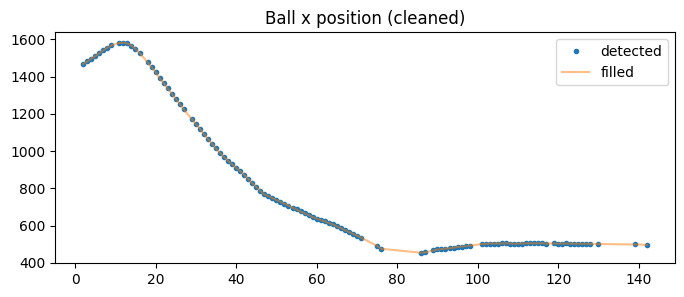

In [19]:
ball = dets[dets.cls == 0].sort_values("conf", ascending=False).drop_duplicates("frame").copy()
ball["cx"] = (ball.x1 + ball.x2) / 2
ball["cy"] = (ball.y1 + ball.y2) / 2
b = ball.set_index("frame").reindex(range(N_FRAMES))[["conf", "cx", "cy"]]

for c in ["cx", "cy"]:                    # remove sudden jumps (false detections)
    med = b[c].rolling(9, center=True, min_periods=3).median()
    b.loc[(b[c] - med).abs() > 150, ["cx", "cy"]] = np.nan

b["detected"] = b.cx.notna()
b["cx_i"] = b.cx.interpolate(limit=10, limit_area="inside")   # fill short gaps only
b["cy_i"] = b.cy.interpolate(limit=10, limit_area="inside")

print("ball detected (after removing jumps):", round(100 * b.detected.mean()), "%")
print("ball after filling gaps up to 10 frames:", round(100 * b.cx_i.notna().mean()), "%")
b.reset_index().to_csv(OUT / "ball_clean.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(b.cx, ".", label="detected"); ax.plot(b.cx_i, "-", alpha=.5, label="filled")
ax.set_title("Ball x position (cleaned)"); ax.legend();plt.savefig("../outputs/ball_clean.png", dpi=150); plt.show()

In [20]:
TEAM_BGR = {0: (255, 120, 0), 1: (0, 0, 255), -1: (0, 255, 255), -2: (160, 160, 160)}
cap = cv2.VideoCapture(str(VIDEO)); cap.set(cv2.CAP_PROP_POS_FRAMES, START)
W, H = int(cap.get(3)), int(cap.get(4))
out = cv2.VideoWriter(str(OUT / "tracked.mp4"), cv2.VideoWriter_fourcc(*"mp4v"), FPS, (W, H))
by_frame = tr.groupby("frame")

for k in range(N_FRAMES):
    ok, frame = cap.read()
    if not ok: break
    if k in by_frame.groups:
        for _, r in by_frame.get_group(k).iterrows():
            c = TEAM_BGR[int(r.team)]
            cv2.rectangle(frame, (int(r.x1), int(r.y1)), (int(r.x2), int(r.y2)), c, 2)
            cv2.putText(frame, str(int(r.track_id)), (int(r.x1), int(r.y1) - 4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, c, 2)
    if k in b.index and not np.isnan(b.loc[k, "cx_i"]):
        col_ball = (0, 255, 0) if b.loc[k, "detected"] else (0, 200, 255)   # green = detected, orange = filled
        cv2.circle(frame, (int(b.loc[k, "cx_i"]), int(b.loc[k, "cy_i"])), 14, col_ball, 3)
    out.write(frame)
cap.release(); out.release()
print("saved", OUT / "tracked.mp4")

saved c:\Users\seree\OneDrive\Desktop\FalseNine\outputs\04_tracking\tracked.mp4


people per frame: mean 12.1 min 6 max 17
players per team per frame (mean): {0: 6.1, 1: 3.9}
track IDs: 33 | full-clip tracks: 2 | shorter than 1s: 15
people per frame: mean 12.1 min 6 max 17
players per team per frame (mean): {0: 6.1, 1: 3.9}
track IDs: 33 | full-clip tracks: 2 | shorter than 1s: 15


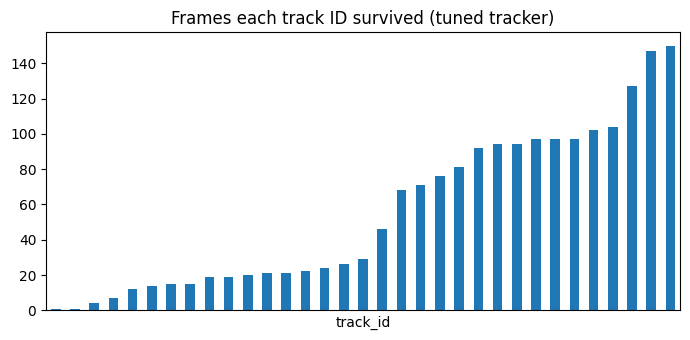

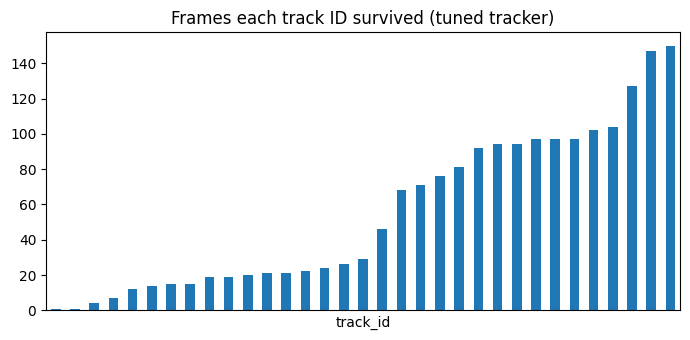

In [21]:
per_frame = tr.groupby("frame").size()
lengths = tr.groupby("track_id").size()
team_per_frame = tr[tr.team >= 0].groupby(["frame", "team"]).size().unstack(fill_value=0)

print("people per frame: mean", per_frame.mean().round(1), "min", per_frame.min(), "max", per_frame.max())
print("players per team per frame (mean):", team_per_frame.mean().round(1).to_dict())
print("track IDs:", len(lengths), "| full-clip tracks:", int((lengths >= 0.9 * N_FRAMES).sum()),
      "| shorter than 1s:", int((lengths < FPS).sum()))

fig, ax = plt.subplots(figsize=(7, 3.5))
lengths.sort_values().plot.bar(ax=ax, title="Frames each track ID survived (tuned tracker)")
ax.set_xticks([]); plt.tight_layout()
plt.savefig(OUT / "tracking_summary.png", dpi=150);per_frame = tr.groupby("frame").size()
lengths = tr.groupby("track_id").size()
team_per_frame = tr[tr.team >= 0].groupby(["frame", "team"]).size().unstack(fill_value=0)

print("people per frame: mean", per_frame.mean().round(1), "min", per_frame.min(), "max", per_frame.max())
print("players per team per frame (mean):", team_per_frame.mean().round(1).to_dict())
print("track IDs:", len(lengths), "| full-clip tracks:", int((lengths >= 0.9 * N_FRAMES).sum()),
      "| shorter than 1s:", int((lengths < FPS).sum()))

fig, ax = plt.subplots(figsize=(7, 3.5))
lengths.sort_values().plot.bar(ax=ax, title="Frames each track ID survived (tuned tracker)")
ax.set_xticks([]); plt.tight_layout()
plt.savefig(OUT / "tracking_summary.png", dpi=150);plt.savefig("../outputs/tracking_summary.png", dpi=150); plt.show()

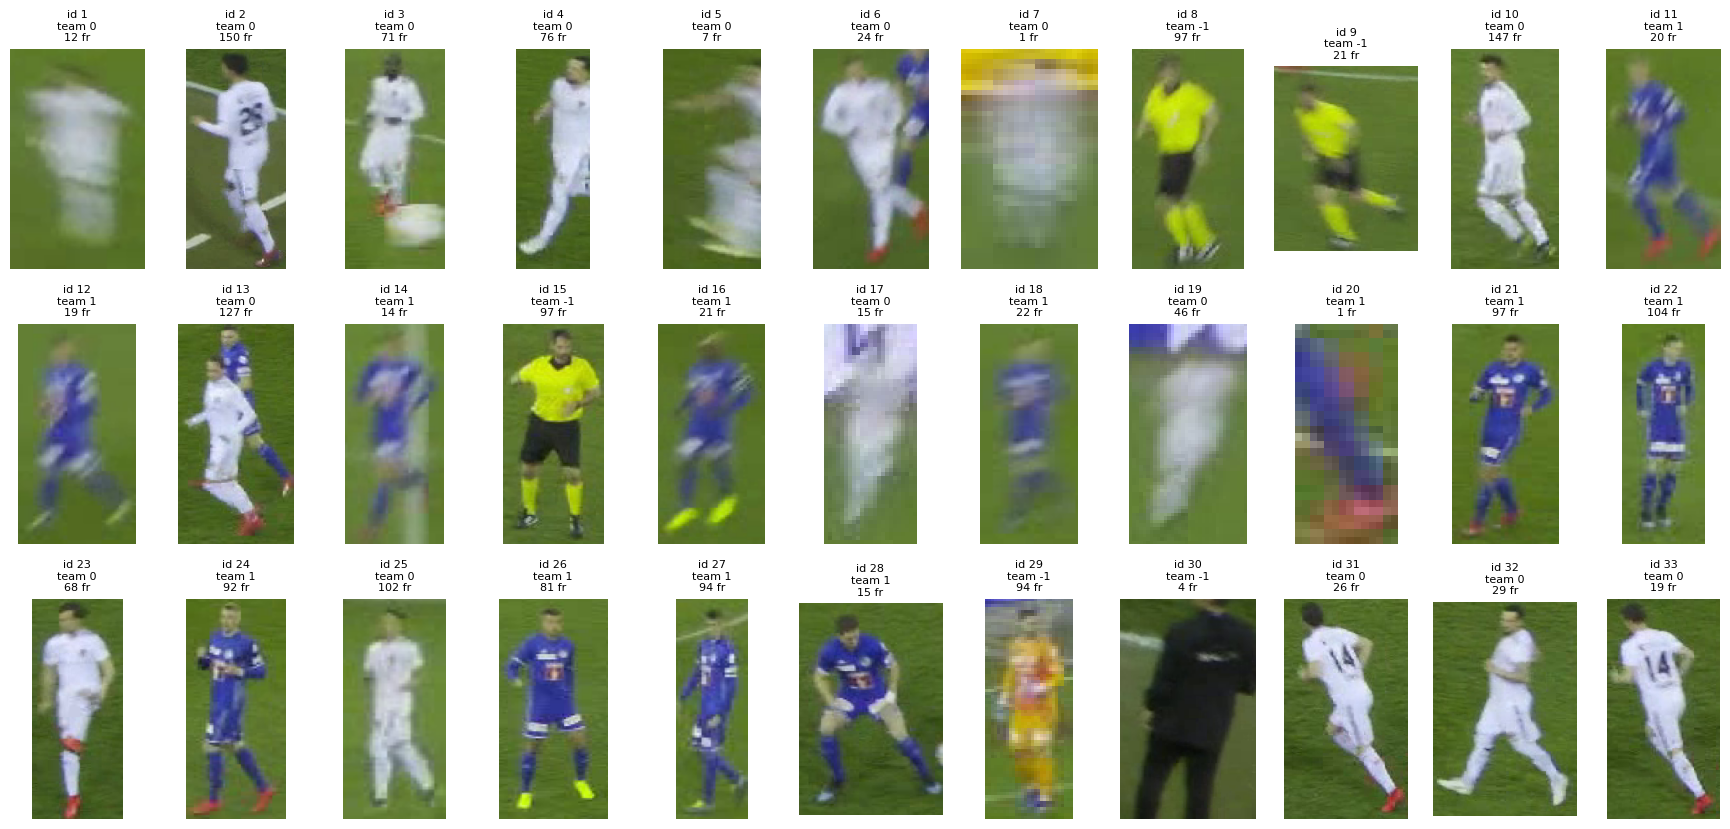

In [22]:
cap = cv2.VideoCapture(str(VIDEO))
tr["h"] = tr.y2 - tr.y1
best = tr.loc[tr.groupby("track_id").h.idxmax()].sort_values("track_id")   # biggest view of each track
lens = tr.groupby("track_id").size()

cols = 11
rows_n = int(np.ceil(len(best) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 1.6, rows_n * 2.8))
axes = np.array(axes).ravel()
for ax in axes: ax.axis("off")

for ax, (_, r) in zip(axes, best.iterrows()):
    cap.set(cv2.CAP_PROP_POS_FRAMES, START + int(r.frame))
    ok, f = cap.read()
    if not ok: continue
    crop = f[max(0, int(r.y1)):int(r.y2), max(0, int(r.x1)):int(r.x2)]
    if crop.size == 0: continue
    ax.imshow(crop[..., ::-1])
    ax.set_title(f"id {int(r.track_id)}\nteam {int(r.team)}\n{lens[r.track_id]} fr", fontsize=8)
cap.release()
plt.tight_layout()
plt.savefig(OUT / "track_contact_sheet.png", dpi=130)
plt.show()

## Findings (SoccerNet clip, 150 frames = 6 s, model trained on a different match)
- Detection transfers: all players on the pitch were boxed, but the model's Player/Ref label did NOT
  transfer. Blue-shirt players were labelled "Ref" (the training match's referee wore dark clothes).
  The pipeline therefore ignores the model's Ref class and groups people by shirt colour instead.
- Teams: k-means on per-track shirt colour (Lab space, K=4, tracks seen 10+ frames), the two biggest
  colour groups = teams, small odd groups = referee / goalkeeper / staff. Mean players per team per
  frame: 8 and 7. Checked by eye on a contact sheet of every track and on the output video.
- Known weakness: goalkeeper has its own shirt colour, so it is labelled "other", not assigned to a team.
  To be fixed later with pitch position.
- Tracking (ByteTrack on image coordinates, 33 IDs, 2 tracks last the whole clip, 15 shorter than 1 s).
  Making the matching more forgiving cut IDs 43 -> 33 and broken tracks 27 -> 15; a longer memory
  and low-confidence boxes changed almost nothing. IDs break mostly when the camera pans, because
  the tracker predicts motion in image space. Not measured against ground truth yet.
- Ball: detected in 74% of frames after removing impossible jumps (5 false detections), 94% after
  filling gaps of up to 10 frames. No values were filled at the clip edges.
- Speed: detection took about 5 min for 150 frames on CPU at 1280 px.
- Limits: one 6-second clip, no ground-truth IDs yet, colours blur in fast motion.